# Notebook 3 — Trabalhando no domínio da frequência
## GW150914 | LIGO Hanford (H1) | Campanha O1

**Objetivo:**
Explorar os dados reais do GW150914 nos domínios do tempo e da frequência, calculando:
* série de Fourier;
* transformada rápida de Fourier (FFT);
* densidade espectral de potência (PSD);
* densidade espectral de amplitude (ASD);

> **Como trabalhar:** Execute as células na ordem. Nas pausas **Observe**, interprete os resultados e compare sua saída com a projetada em sala.

**Origem:** Material adaptado de [Introduction to GWOSC Data](https://github.com/gwosc-tutorial/introduction_gwosc_data), sob licença GPL-3.0 ou posterior.

**Adaptação didática:** Ronai Lisbôa — UFRN.

# 1. Série de Fourier. Uma analogia do som.

Qualquer sinal periódico pode ser decomposto em uma soma de funções senoidais por meio da série de Fourier. Nessa decomposição, o sinal é escrito como a superposição da frequência fundamental e de seus harmônicos, cada um contribuindo com determinada amplitude e fase.

$$y(x,t) = \sum_{n=1}^{∞} A_n \sin(k_n x)\cos(2\pi f_n t + \phi_n)$$

Na imagem abaixo, o som composto é representado pela superposição de ondas senoidais puras correspondentes ao modo fundamental, $(f_1 = 220)$ Hz e ao segundo harmônico $(f_2 = 440)$ Hz e ao terceiro harmônico $(f_3 = 880)$ Hz.

<div align="center">

<img src="https://raw.githubusercontent.com/Ronai/gwd/3ce9679150740c3c7dabd4d77e0bfe64152dbc20/introduction_gwosc_data/img/ligo%20-%20fourier1.png" width="750">

</div>

As diferentes amplitudes $A_n$ dos harmônicos presentes em um sinal sonoro contribuem para determinar seu **timbre**, permitindo distinguir sons de mesma frequência fundamental produzidos por diferentes instrumentos musicais.

<div align="center">

<img src="https://raw.githubusercontent.com/Ronai/gwd/3ce9679150740c3c7dabd4d77e0bfe64152dbc20/introduction_gwosc_data/img/ligo%20-%20fourier2.png" width="750">

</div>

A análise de Fourier permite identificar as frequências presentes no sinal e suas respectivas amplitudes. Para um sinal periódico $y(t)$, os coeficientes de Fourier são calculados por

$$
a_n=\frac{2}{T}\int_0^T y(t)\cos(2\pi nf_1t)\,dt
$$

e

$$
b_n=\frac{2}{T}\int_0^T y(t)\sin(2\pi nf_1t)\,dt,
$$

sendo $T$ o período do sinal e $f_1=1/T$ sua frequência fundamental.

A amplitude do $n$-ésimo harmônico é dada por

$$
A_n=\sqrt{a_n^2+b_n^2}.
$$

No domínio da frequência, os picos do espectro indicam as componentes harmônicas presentes no sinal.

A aplicação de filtros permite **atenuar ou amplificar determinadas faixas de frequência**, modificando as amplitudes relativas dos harmônicos e, consequentemente, o timbre do som.

A [transformada de Fourier](https://en.wikipedia.org/wiki/Fourier_transform) representa os dados em termos de componentes de frequência.

**A análise espectral é especialmente importante porque o ruído dos interferômetros não tem a mesma intensidade em todas as frequências**.

##1.1 Gerando um sinal composto

Vamos transformar um sinal qualquer do domínio do tempo para o domínio da frequência. Primeiramente, vamos simular um sinal calculando uma série de Fourier com apenas três parcelas.

In [ ]:

# ---------------------------------------------------
# Criar um sinal composto por três ondas senoidais
# ---------------------------------------------------
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

# -- Definir os parâmetros de amostragem
fs = 2000                   # Frequência de amostragem (Hz)
dt = 1 / fs                 # Intervalo entre amostras (s)
T = 5.0                     # Duração total (s)

# -- Construir o vetor de tempo
time = np.arange(0, T, dt)

# -- Definir três ondas senoidais
sine1 = np.sin(2*np.pi*190*time)  # f1 = 190 Hz
sine2 = np.sin(2*np.pi*220*time)  # f2 = 220 Hz
sine3 = np.sin(2*np.pi*310*time)  # f3 = 310 Hz

# -- Somar as componentes
data = sine1 + sine2 + sine3

# -- Parâmetros da série temporal completa
N = len(time)
df = fs / N
f_nyquist = fs / 2

print(f"Número de amostras (N): {N}")
print(f"Intervalo entre amostras (dt): {dt:.6f} s")
print(f"Frequência de amostragem (fs): {fs:.0f} Hz")
print(f"Duração total (T): {T:.1f} s")
print(f"Espaçamento espectral (df): {df:.2f} Hz")
print(f"Frequência de Nyquist: {f_nyquist:.0f} Hz")

# -- Visualizar o sinal no domínio do tempo
plt.plot(time, data)
plt.title("Sinal no domínio do tempo")
plt.xlim(2.0, 2.1)                       # Intervalo mostrado no gráfico
plt.xlabel("Tempo (s)")
plt.ylabel("Amplitude")
plt.grid()
plt.show()


##2.2 Funções de janelamento (*windowing*)

Podem existir descontinuidades nas extremidades de um sinal de uma série temporal e isso precisa ser tratado antes de calcular a transformada de Fourier.

Essas descontinuidades produzem o chamado **vazamento espectral** (*spectral leakage*), espalhando energia por frequências próximas. O janelamento reduz esse efeito, embora também modifique as amplitudes e alargue os picos espectrais.

Há diferentes tipos de janelas: Tukey, Ham, Blackman e muitas outras [Window function](https://en.wikipedia.org/wiki/Window_function).

<div align="center">

<img src="https://raw.githubusercontent.com/Ronai/gwd/e5a1d2d562d1b1d7407eceb9ab2a52cdc6684551/introduction_gwosc_data/img/ligo%20-%20window.png" width="750">

</div>


### Janela de Tukey

Para uma janela com $N$ amostras, definimos

$$
u=\frac{n}{N-1}, \qquad n=0,\ldots,N-1.
$$

A janelamento de Tukey é dada por

$$
w(u)=
\begin{cases}
\frac{1}{2}\left[1-\cos\left(\frac{2\pi u}{\alpha}\right)\right],
& 0\leq u<\frac{\alpha}{2},\\[6pt]
1,
& \frac{\alpha}{2}\leq u\leq1-\frac{\alpha}{2},\\[6pt]
\frac{1}{2}\left[1-\cos\left(\frac{2\pi(1-u)}{\alpha}\right)\right],
& 1-\frac{\alpha}{2} <u \leq1
\end{cases}
$$

Essa expressão considera $0<\alpha\leq1$ e a convenção de janela simétrica.

A aplicação da janela ao sinal corresponde à multiplicação ponto a ponto:

$$
x_{\mathrm{janela}}[n]=w[n]x[n].
$$

A janela de Tukey reduz as descontinuidades nas extremidades do registro temporal, diminuindo os efeitos do vazamento espectral. Entretanto, como outras funções janela, também modifica as amplitudes e a largura dos picos espectrais.

No exemplo a seguir, utilizaremos $\alpha=0{,}5$, que é o valor padrão da função `scipy.signal.windows.tukey()`.

In [ ]:
# ---------------------------------------------------
# Visualizando a janela Tukey
# ---------------------------------------------------
from scipy import signal

# Selecionar o intervalo de 2 a 2,1 segundos
selecao = (time >= 2) & (time < 2.1)

t = time[selecao]
x = data[selecao]

# Calcular os parâmetros de amostragem
N = len(x)
dt = t[1] - t[0]
fs = 1 / dt
T = N * dt
df = 1 / T

print(f"Número de amostras (N): {N}")
print(f"Intervalo de amostragem (dt): {dt:.6f} s")
print(f"Frequência de amostragem (fs): {fs:.0f} Hz")
print(f"Duração (T): {T:.3f} s")
print(f"Espaçamento espectral (df): {df:.1f} Hz")


# Representar somente o trecho selecionado
plt.plot(t, x)
plt.xlabel("Tempo (s)")
plt.ylabel("Amplitude")
plt.title("Sinal no domínio do tempo — 2,0 a 2,1 s")
plt.grid()
plt.show()

# Criar a janela de Tukey
window = signal.windows.tukey(len(x))

# Visualizar a janela no intervalo de 2.0 s a 2.1 s.
plt.plot(t, window)
plt.xlabel("Tempo (s)")
plt.ylabel("Amplitude da janela")
plt.title("Janela de Tukey — 2 a 2,1 s")
plt.grid()
plt.show()


In [ ]:
# Criar a janela de Tukey
window = signal.windows.tukey(len(x))

# Normalizar o sinal para visualização
x_norm = x / np.max(np.abs(x))

plt.figure(figsize=(11, 4))

plt.plot(t, x_norm, label="Sinal normalizado", color="blue")
plt.plot(t, window, label="Janela de Tukey", color="red", linestyle="--", linewidth=2)

plt.xlabel("Tempo (s)")
plt.ylabel("Amplitude normalizada")
plt.title("Sinal e janela de Tukey — 2,0 a 2,1 s")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

#2. A Transformada Discreta de Fourier (DFT)

A **transformada de Fourier** é uma ferramenta matemática amplamente utilizada para analisar o conteúdo em frequência de um sinal originalmente representado no domínio do tempo. Ela permite identificar as frequências presentes no sinal e avaliar suas contribuições relativas.

Enquanto a série de Fourier representa funções periódicas como uma superposição de componentes harmônicas, a transformada de Fourier permite analisar também sinais não periódicos.

Na análise computacional, os sinais são representados por sequências de valores amostrados em instantes discretos. Nesse contexto, utilizamos a **Transformada Discreta de Fourier (DFT)**, que decompõe uma sequência de dados em componentes de frequência discretas.

<div align="center">

<img src="https://raw.githubusercontent.com/Ronai/gwd/c4c8b0e468505c4b14eb4804bdc62353ad1b49d9/introduction_gwosc_data/img/ligo%20-%20dft.png" width="750">

</div>


#3. A Transformada Rápida de Fourier (FFT)

Na prática, o cálculo da DFT é geralmente realizado por meio da **Transformada Rápida de Fourier (Fast Fourier Transform)**, um algoritmo que reduz significativamente o custo computacional da transformação.

Para um sinal discreto $a_m$, contendo $N$ amostras, a DFT é definida por

$$
\boxed{
A_k=\sum_{m=0}^{N-1}a_m e^{-2\pi i mk/N},
\qquad k=0,1,\ldots,N-1.
}
$$

Nessa expressão:

- $a_m$ representa o valor do sinal na amostra $m$;
- $N$ é o número total de amostras;
- $k$ identifica o índice da componente de frequência;
- $A_k$ é o coeficiente complexo associado à frequência correspondente.


Os coeficientes $A_k$ são, em geral, números complexos. Seu módulo, $|A_k|$, está relacionado à amplitude da componente de frequência, enquanto seu argumento, $\arg(A_k)$, fornece a informação de fase.

Se o sinal foi amostrado com frequência $f_s$, a resolução em frequência é dada por

$$
\Delta f=\frac{f_s}{N}=\frac{1}{T},
$$

em que $T=N/f_s$ é a duração total do sinal.

Para as frequências não negativas, os índices da DFT correspondem às frequências

$$
f_k=k\Delta f.
$$

As frequências discretas são calculadas por:

$$f_k = k \frac{f_s}{N}$$

em que $$k=0,1,\ldots,\lfloor N/2\rfloor.$$

##3.1 Exemplo com os parâmetros do notebook

Considere um sinal amostrado com frequência

$$
f_s=2000\,\mathrm{Hz}
$$

durante um intervalo

$$
T=0{,}1\,\mathrm{s}.
$$

O intervalo entre amostras é

$$
\Delta t=\frac{1}{f_s}=0{,}0005\,\mathrm{s}.
$$

O número de amostras será

$$
N=f_sT=2000\times0{,}1=200.
$$

O espaçamento entre as frequências da DFT é

$$
\Delta f=\frac{f_s}{N}=\frac{2000}{200}.
$$

Portanto,

$$
\boxed{\Delta f=10\,\mathrm{Hz}}.
$$

As frequências discretas são dadas por

$$
f_k=k\Delta f,
\qquad k=0,1,\ldots,\frac{N}{2}.
$$

Assim, o vetor de frequências não negativas contém

$$
\boxed{f_k=[0,10,20,\ldots,980,990,1000]\ \mathrm{Hz}}.
$$

O valor máximo corresponde à frequência de Nyquist:

$$
f_{\mathrm{Nyquist}}=\frac{f_s}{2}
=\frac{2000}{2}=1000\,\mathrm{Hz}.
$$

Portanto, a FFT real fornece $101$ componentes de frequência, separadas por $10 \mathrm{Hz}$, entre $0$ e $1000 \mathrm{Hz}$.

Como $\Delta f=10\ \mathrm{Hz}$, essas frequências correspondem exatamente aos índices:

| Frequência $f$ | Índice $k$ |
|:---:|:---:|
| 190 Hz | 19 |
| 220 Hz | 22 |
| 310 Hz | 31 |


Portanto, as três frequências coincidem com bins da DFT.

Isso é interessante para a demonstração com a janela de Tukey: sem janela, a FFT ideal já concentra as componentes nesses bins. Ao aplicar a janela de Tukey, você suaviza as extremidades, mas também introduz um alargamento dos picos espectrais.

##3.2 As funções Python para as TFTs

A função `np.fft.fft()` retorna componentes associadas às frequências positivas e negativas.

A função `np.fft.rfft()` retorna apenas as componentes de frequência não negativa, evitando informações redundantes.

Por exemplo, para $N=200$ amostras:
- np.fft.fft(data) retorna 200 valores;
- np.fft.rfft(data) retorna 101 valores.

A função `np.fft.rfftfreq()` constrói o vetor de frequências correspondente aos valores calculados pela `np.fft.rfft()`.
É importante distinguir as funções:
- rfft() calcula as componentes espectrais do sinal.
- rfftfreq() informa a frequência física associada a cada componente.

Finalmente, quando não fornecemos o intervalo entre amostras, o NumPy considera $d=1$. Assim, as frequências são expressas em ciclos por amostra.

Para obter diretamente as frequências em hertz, devemos fornecer o intervalo de amostragem:

$$ \Delta t = \frac{1}{f_s} = 0,0005 \mathrm{ s}.$$


In [ ]:
# Importar o módulo de processamento de sinais
from scipy import signal

# Número de amostras e intervalo entre amostras
N = len(data)
dt = 1 / fs

# Criar uma janela de Tukey
window = signal.windows.tukey(N)

# Aplicar a janela aos dados
data_window = window * data

# Calcular a FFT dos dados reais em uma janela Tukey
data_freq = np.fft.rfft(data_window)

# Construir o vetor de frequências em Hz
frequencies = np.fft.rfftfreq(N, d=dt)

# Representar a magnitude da FFT
plt.plot(frequencies, np.abs(data_freq))
plt.xlim(150, 350)
plt.xlabel('Frequência (Hz)')
plt.ylabel('Magnitude da FFT')
plt.title('Sinal no domínio da frequência')
plt.grid()

In [ ]:
# -- Por fim, podemos voltar ao domínio do tempo
# -- usando a Transformada Inversa de Fourier (IFFT)

data_after_ifft = np.fft.irfft(data_freq)

plt.plot(time, data, label='Dados originais')
plt.plot(time,data_after_ifft, '--', label='Dados após IFFT')
plt.title('Sinal no domínio do tempo')
plt.xlim(2, 2.1)
plt.xlabel('Tempo (s)')
plt.ylabel('Amplitude')
plt.legend(loc=1)
plt.show()

#4. Trabalhando com dados do evento GW150914

Use o arquivo `H-H1_LOSC_4_V1-1126256640-4096.hdf5`. Ele contém **4096 s** de dados de H1, amostrados a **4096 Hz**.

- **Colab com Drive:** coloque o HDF5 na pasta `dados` do curso no seu Google Drive. Ajuste o caminho `pasta_dados` nas células a seguir se você o salvou em outro lugar no Meu Drive.
- **Colab com arquivo na sessão:** use `pasta_dados = Path("/content")`. Envie o HDF5 pelo painel **Arquivos** caso ele ainda esteja no computador.

> **Observe:** Use `pathlib` para definir o caminho do arquivo, `h5py` para ler o HDF5, `NumPy` para trabalhar com as amostras e `Matplotlib` para gerar os gráficos.

In [ ]:
#----------------------------------------------------------
# Preparando o notebook
#----------------------------------------------------------
# Importar as bibliotecas e preparar os gráficos
# Path indica o caminho do arquivo; h5py lê o HDF5.
# NumPy trabalha com as amostras; Matplotlib gera os gráficos.

from pathlib import Path

import h5py
import matplotlib.pyplot as plt
import numpy as np

# Tamanho das figuras e das fontes para projeção em sala.
plt.rcParams.update({"figure.figsize": (11, 4), "font.size": 14})

In [ ]:
#----------------------------------------------------------
# Localizar o arquivo HDF5
#----------------------------------------------------------

# Indique a pasta onde foi salvo o arquivo baixado no Notebook 1.
# Se a pasta estiver no Google Drive, o Colab monta o Drive para acessá-la.

pasta_dados = Path("/content/drive/MyDrive/Colab Notebooks/GWPY-Curso/dados")

if pasta_dados.is_relative_to("/content/drive"):
    from google.colab import drive

    drive.mount("/content/drive")

# Combine a pasta com o nome do arquivo e exiba o caminho completo.
filename = pasta_dados / "H-H1_LOSC_4_V1-1126256640-4096.hdf5"

print(filename.resolve())

In [ ]:
#----------------------------------------------------------
# Parâmetros de amostragem e resolução espectral — H1
#----------------------------------------------------------

# Ler os metadados sem carregar os dados de strain
with h5py.File(filename, "r") as dados:
    serie = dados["strain"]["Strain"]
    gps_start = int(dados["meta"]["GPSstart"][()])
    dt = float(serie.attrs["Xspacing"])
    N = len(serie)

# Grandezas fundamentais
fs = 1 / dt               # Frequência de amostragem
f_nyquist = fs / 2        # Frequência de Nyquist
T = N * dt                # Duração da série temporal
df = 1 / T                # Espaçamento espectral da DFT

# Exibir os resultados
print(f"GPS inicial: {gps_start}")
print(f"Número de amostras (N): {N:,}")
print(f"Intervalo de amostragem (Δt): {dt:.9f} s")
print(f"Frequência de amostragem (fs): {fs:.0f} Hz")
print(f"Frequência de Nyquist: {f_nyquist:.0f} Hz")
print(f"Duração total (T): {T:.0f} s")
print(f"Espaçamento espectral (Δf): {df:.9f} Hz")


## 4. Carregar apenas os trechos necessários

Como vimos no Notebook 02, o *strain* está no conjunto de dados `strain/Strain` e o intervalo entre amostras é o atributo `Xspacing`.

O arquivo completo possui **16.777.216 amostras**. Sem carregar o *strain* completo na memória, vamos extrair duas janelas diretamente do HDF5:

- **Janela do evento:** 16 s, de 8 s antes até 8 s depois do instante GPS do GW150914. Será usada na FFT.
- **Janela de referência:** 128 s, entre 200 s e 72 s antes do evento. Será usada para caracterizar o ruído sem incluir a coalescência.

A série temporal medida pelo detector pode ser representada por
$$
s(t)=h(t)+n(t),
$$

em que:
- $s(t)$ é o strain medido pelo detector;
- $h(t)$ é o sinal gravitacional;
- $n(t)$ é o ruído instrumental.

Quando aplicamos o janelamento e calculamos a FFT, obtemos

$$
\widetilde{s}_w(f)
=F\left\{w(t)[h(t)+n(t)]\right\}.
$$

Portanto, o resultado continua contendo o sinal gravitacional e o ruído. A janela apenas reduz o vazamento espectral causado pelo recorte temporal.

O janelamento nos 16 segundos de dados do H1 próximos ao GW150914 não remove o ruído instrumental.

Os dados anteriores ao evento serão utilizados para estimar as características do ruído, e não para subtraí-lo diretamente do sinal.

In [ ]:
#----------------------------------------------------------
# Selecionar os trechos para análise — GW150914 (H1)
#----------------------------------------------------------

GPS_EVENTO = 1126259462.4

# Janela do evento — 16 segundos
inicio_evento = GPS_EVENTO - 8

# Janela de referência — 128 segundos
inicio_ruido = GPS_EVENTO - 200

# Ler somente os trechos necessários do arquivo HDF5
with h5py.File(filename, "r") as dados:
    serie = dados["strain"]["Strain"]

    i0 = int(round((inicio_evento - gps_start) / dt))
    i1 = int(round((inicio_ruido - gps_start) / dt))

    strain_seg = serie[i0:i0 + int(round(16 * fs))]
    strain_ruido = serie[i1:i1 + int(round(128 * fs))]

# Tempo relativo ao instante do GW150914
t_seg = gps_start + (i0 + np.arange(len(strain_seg))) * dt - GPS_EVENTO

# Tempo relativo ao evento para a janela de referência
t_ruido = inicio_ruido - GPS_EVENTO + np.arange(len(strain_ruido)) * dt


print("Amostras do evento: N_evento =", len(strain_seg))
print("Amostras de referência: N_ruido =", len(strain_ruido))

In [ ]:
#----------------------------------------------------------
# Visualização das duas janelas — GW150914 (H1)
#----------------------------------------------------------

fig, ax = plt.subplots(2, 1, figsize=(11, 7))

# Janela do evento: 16 segundos
ax[0].plot(t_seg, strain_seg, lw=0.55)
ax[0].axvline(0, ls="--", color="red", label="GW150914")
ax[0].set(
    xlabel="Tempo relativo ao GW150914 (s)",
    ylabel="Strain H1",
    title="Janela do evento — 16 s (FFT)"
)
ax[0].grid(alpha=0.25)
ax[0].legend()


# Janela de referência: 128 segundos
ax[1].plot(t_ruido, strain_ruido, lw=0.55)
ax[1].set(
    xlabel="Tempo relativo ao GW150914 (s)",
    ylabel="Strain H1",
    title="Janela de referência — 128 s (PSD e ASD)"
)
ax[1].grid(alpha=0.25)

plt.tight_layout()
plt.show()


#5. FFT e janela de Blackman

Após estudar o fenômeno do vazamento espectral utilizando um sinal sintético composto por ondas senoidais, aplicaremos agora a **Transformada Rápida de Fourier (FFT)** aos dados reais do detector LIGO Hanford (H1), em um intervalo de 16 segundos ao redor do evento GW150914.

Como estamos analisando um intervalo temporal finito, o recorte dos dados pode introduzir descontinuidades nas extremidades do sinal, produzindo **vazamento espectral**. Esse efeito faz com que a contribuição de uma determinada frequência se espalhe por outras componentes do espectro.

Para reduzir esse efeito, aplicaremos uma **janela de Hann** antes de calcular a FFT. Essa janela suaviza as extremidades do sinal e atenua os lóbulos laterais do espectro. Entretanto, o janelamento também modifica as amplitudes e provoca um alargamento dos picos espectrais.

Para compensar a atenuação introduzida pela janela, normalizaremos o módulo da FFT pela soma dos valores da janela, incluindo o fator correspondente ao espectro unilateral. Esse procedimento permite estimar as amplitudes de componentes senoidais isoladas, especialmente quando suas frequências coincidem com os bins da DFT.

É importante observar que a FFT fornece informações sobre o **conteúdo em frequência do sinal ao longo dos 16 segundos analisados**, mas não permite identificar diretamente em que instante cada componente de frequência esteve presente.

Essa limitação é particularmente relevante para o GW150914, cujo sinal apresenta uma evolução característica de frequência e amplitude ao longo do tempo, conhecida como ***chirp***. Para investigar essa evolução, será necessário utilizar uma representação que combine informações temporais e espectrais, como o **espectrograma**.

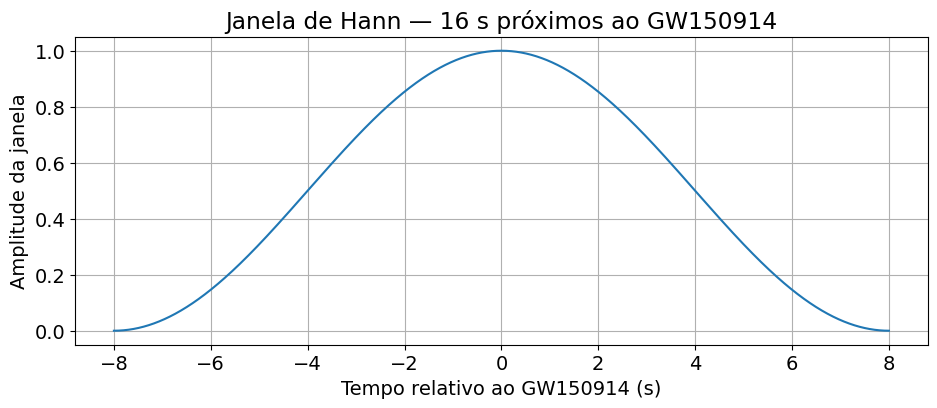

In [64]:
#----------------------------------------------------------
# Visualizando a janela de Hann — GW150914 (H1)
#----------------------------------------------------------

# Criar a janela de Hann com o mesmo número de amostras
window = signal.windows.hann(len(strain_seg))

# Visualizar a janela no intervalo de -8 s a +8 s
plt.figure(figsize=(11, 4))
plt.plot(t_seg, window)

plt.xlabel("Tempo relativo ao GW150914 (s)")
plt.ylabel("Amplitude da janela")
plt.title("Janela de Hann — 16 s próximos ao GW150914")
plt.grid()
plt.show()


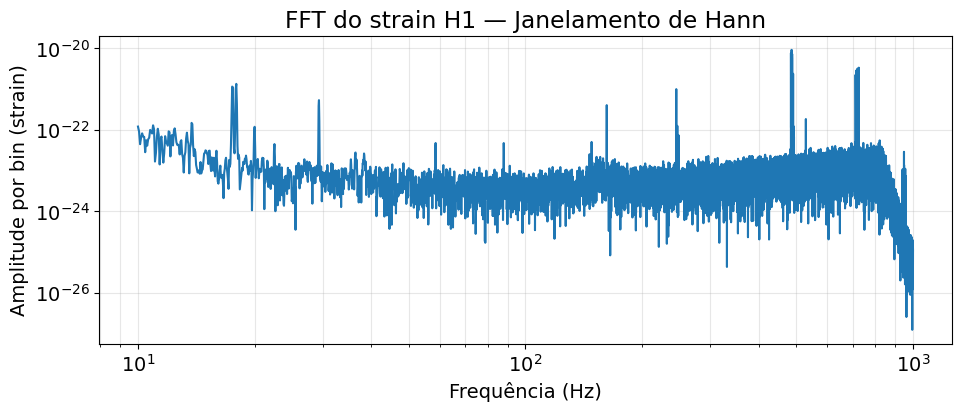

In [68]:
#----------------------------------------------------------
# FFT do strain H1 — GW150914
#----------------------------------------------------------

# Remover a média do sinal
dados_centrados = strain_seg - np.mean(strain_seg)

# Aplicar a janela de Hann
janela = signal.windows.hann(len(dados_centrados))
dados_janelados = dados_centrados * janela

# Calcular a FFT e as frequências correspondentes
fft = np.fft.rfft(dados_janelados)
freq = np.fft.rfftfreq(len(dados_janelados), d=dt)

# Normalizar a amplitude
amplitude = 2 * np.abs(fft) / np.sum(janela)

# Selecionar o intervalo de 10 a 1000 Hz
faixa = (freq >= 10) & (freq <= 1000)

# Representar o espectro
fig, ax = plt.subplots(figsize=(11, 4))

ax.loglog(freq[faixa], amplitude[faixa])

ax.set(
    xlabel="Frequência (Hz)",
    ylabel="Amplitude por bin (strain)",
    title="FFT do strain H1 — Janelamento de Hann"
)

ax.grid(True, which="both", alpha=0.3)
plt.show()


#6. Densidade espectral de potência — PSD

A **PSD** (*Power Spectral Density*) descreve como a variância/potência média do *strain* se distribui entre as frequências. Sua unidade é **strain²/Hz** (o *strain* é adimensional).

Para estimar a PSD, usaremos o **método de Welch**, que divide os dados em trechos menores, calcula os espectros e faz uma média entre eles. A média dos periodogramas reduz a variabilidade da estimativa em relação a um periodograma isolado, embora a segmentação também altere a resolução em frequência.

##Como funciona o método de Welch?

Dividimos os 128 segundos de referência anteriores ao GW150914 em **segmentos de 4 segundos**, com **2 segundos de sobreposição**. Aplicamos uma janela Hann a cada trecho, calculamos seus periodogramas e fazemos a **média aritmética dessas estimativas**. O janelamento de Hann reduz o vazamento **dentro de cada segmento**; o método de Welch reduz a variabilidade da estimativa ao combinar vários segmentos.

A média por periodogramas do método de Welch **não dá peso maior aos segmentos centrais**. Uma estimativa baseada na **mediana**, usada em algumas ferramentas de análise, é uma alternativa mais robusta a certos valores discrepantes, mas não é o procedimento escolhido aqui.

**Importante:** vamos utilizar os **128 segundos de referência antes do evento**. Assim, a curva representa sobretudo o ruído naquele intervalo, e não a contribuição localizada do GW150914. O trecho pode conter outras perturbações instrumentais; a seleção rigorosa de dados de qualidade é assunto complementar.

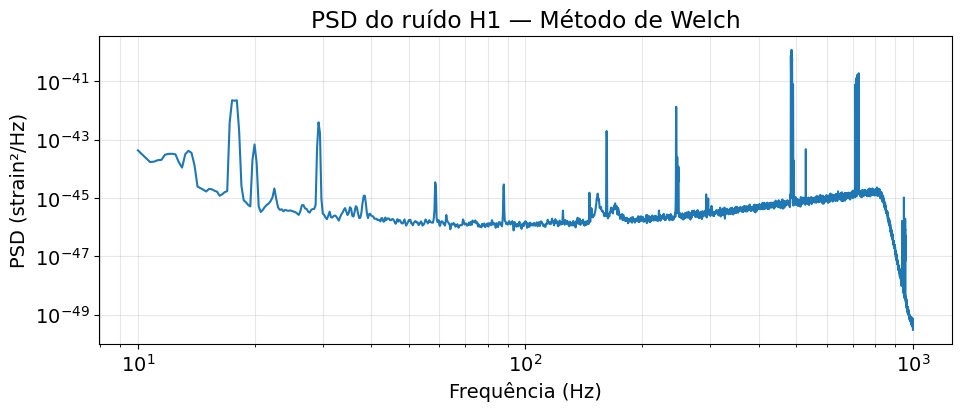

In [69]:
#----------------------------------------------------------
# Densidade Espectral de Potência (PSD) — Método de Welch
#----------------------------------------------------------

from scipy import signal

# Calcular a PSD usando segmentos de 4 s
# com 50% de sobreposição
freq_psd, psd = signal.welch(
    strain_ruido,
    fs=fs,
    window="hann",
    nperseg=int(4 * fs),
    noverlap=int(2 * fs),
    detrend="constant",
    scaling="density"
)

# Selecionar o intervalo de 10 a 1000 Hz
faixa = (freq_psd >= 10) & (freq_psd <= 1000)

# Representar a PSD
fig, ax = plt.subplots(figsize=(11, 4))

ax.loglog(freq_psd[faixa], psd[faixa])

ax.set(
    xlabel="Frequência (Hz)",
    ylabel="PSD (strain²/Hz)",
    title="PSD do ruído H1 — Método de Welch"
)

ax.grid(True, which="both", alpha=0.3)
plt.show()


## 7. Densidade espectral de amplitude — ASD

A **ASD** (*Amplitude Spectral Density*) é a raiz quadrada da PSD:

$$
\mathrm{ASD}(f)=\sqrt{\mathrm{PSD}(f)}.
$$

Sua unidade é **strain/√Hz**. Valores menores da ASD indicam menor ruído instrumental naquela frequência (quando a estimativa é representativa). Observe o perfil da curva e compare as regiões de frequências baixas e intermediárias.

Não confunda **amplitude por bin da FFT** com **ASD**: os dois gráficos têm significados e unidades diferentes.

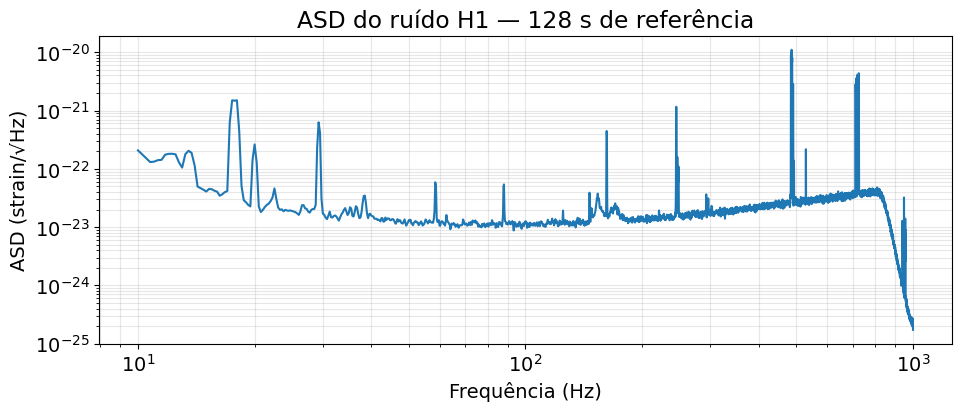

In [70]:

#----------------------------------------------------------
# Densidade Espectral de Amplitude (ASD)
#----------------------------------------------------------

# Calcular a ASD a partir da PSD
asd = np.sqrt(psd)

# Selecionar o intervalo de 10 a 1000 Hz
faixa = (freq_psd >= 10) & (freq_psd <= 1000)

# Representar a ASD
fig, ax = plt.subplots(figsize=(11, 4))

ax.loglog(freq_psd[faixa], asd[faixa])

ax.set(
    xlabel="Frequência (Hz)",
    ylabel="ASD (strain/√Hz)",
    title="ASD do ruído H1 — 128 s de referência"
)

ax.grid(True, which="both", alpha=0.3)
plt.show()


## Interpretando a ASD e a sensibilidade do detector

O gráfico apresenta a **densidade espectral de amplitude (ASD)** do ruído instrumental do detector LIGO Hanford (H1), estimada a partir de 128 segundos de dados anteriores ao GW150914.

A ASD mostra como o ruído se distribui em função da frequência, sendo expressa em $\mathrm{strain}/\sqrt{\mathrm{Hz}}$. **Quanto menor a ASD, menor o ruído e, em geral, melhor a sensibilidade do detector.**

### Como interpretar o gráfico?

1. **Baixas frequências (10–30 Hz):** a ASD é elevada devido a diferentes fontes de ruído, incluindo vibrações sísmicas e efeitos associados à suspensão e ao controle dos espelhos. Abaixo de uma frequência mínima $f_{\min}$, os dados podem não estar devidamente calibrados.

2. **Frequências intermediárias (40–200 Hz):** o ruído diminui significativamente, atingindo valores da ordem de $10^{-23}\,\mathrm{strain}/\sqrt{\mathrm{Hz}}$. Essa é uma das regiões de melhor sensibilidade do detector, importante para a observação do GW150914, cujo conteúdo espectral detectável se concentra principalmente entre 20 e 300 Hz.

3. **Picos estreitos no espectro:** representam linhas de origem instrumental, como ressonâncias mecânicas, sinais de calibração, oscilações de controle (*dither*) e interferências elétricas de 60 Hz e seus harmônicos. A identificação precisa de cada linha exige informações sobre o detector durante O1.

4. **Frequências elevadas (acima de 200 Hz):** o ruído aumenta gradualmente, com contribuição crescente do ruído quântico associado à detecção óptica (*shot noise*). O pico pronunciado próximo de 1000 Hz requer uma investigação específica de sua origem.

### Frequência de amostragem e visualização do sinal

Para dados amostrados a $f_s=4096\,\mathrm{Hz}$, a frequência de Nyquist é:

$$
f_N=\frac{f_s}{2}=2048\,\mathrm{Hz}.
$$

Essa frequência é suficiente para representar o conteúdo espectral detectável do GW150914.

**Por que não vemos o sinal gravitacional?** Porque a ASD foi estimada utilizando 128 segundos de dados anteriores ao evento. Portanto, o gráfico representa essencialmente o ruído instrumental, e não o sinal gravitacional.

A análise da ASD é fundamental para compreender a sensibilidade do detector e orientar técnicas posteriores de filtragem e identificação de ondas gravitacionais.

### Espectrograma

No espectrograma apresentado abaixo, é possível observar uma quantidade significativa de potência espectral em excesso abaixo de aproximadamente $20\,\mathrm{Hz}$, além de linhas espectrais intensas em $500$, $1000$ e $1500\,\mathrm{Hz}$, também evidentes nos gráficos de ASD apresentados anteriormente.

As linhas em frequências múltiplas de $500\,\mathrm{Hz}$ correspondem aos harmônicos dos chamados modos de violino (violin modes), associados às vibrações das fibras que sustentam os espelhos dos interferômetros do LIGO.

O sinal gravitacional é apenas ligeiramente visível neste espectrograma, próximo de $t=0$ e em frequências inferiores a $500\,\mathrm{Hz}$.

Para visualizar melhor o sinal, precisamos ampliar a região próxima ao instante do evento, restringir a faixa de frequências ao intervalo de $20$ a $400\,\mathrm{Hz}$ e utilizar os dados previamente submetidos ao processo de branqueamento (whitening).

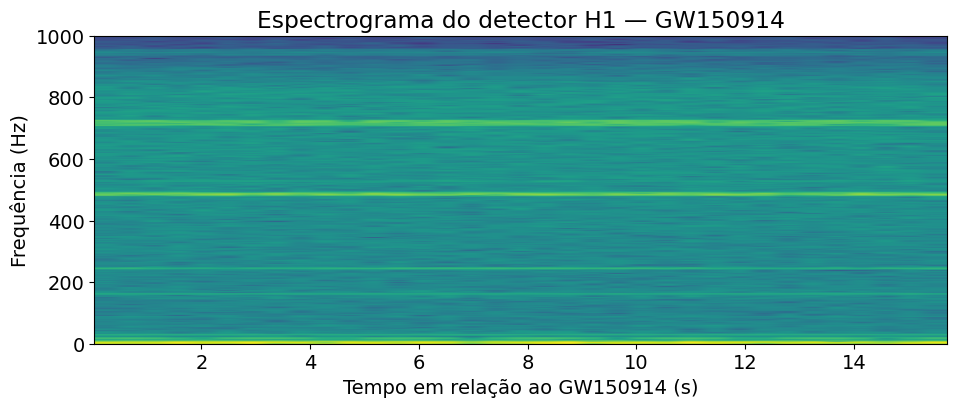

In [71]:
#-------------------
# Make a spectrogram
#-------------------
NFFT = 1024
short_window = np.blackman(NFFT)
spec_power, freqs, bins, im = plt.specgram(
    strain_seg,
    NFFT=NFFT,
    Fs=fs,
    window=short_window,
    cmap='viridis'
)
plt.xlabel("Tempo em relação ao GW150914 (s)")
plt.ylabel("Frequência (Hz)")
plt.title("Espectrograma do detector H1 — GW150914")
plt.show()

## 11. Verificação e exercícios

1. Qual a diferença entre a **amplitude por bin da FFT**, a **PSD** e a **ASD**? Indique as unidades de cada grandeza.
2. Na curva de ASD, em quais faixas de frequência o ruído parece maior e menor? Baseie-se no gráfico calculado, não em valores decorados.
3. Por que a PSD foi estimada a partir de um trecho anterior ao GW150914, em vez de usar exclusivamente a janela de 16 segundos que contém o evento?


**Registre suas respostas em uma célula de texto.**

## Apêncide. Frequência de amostragem e frequência de Nyquist

A frequência de amostragem é definida por

$$
f_s=\frac{1}{\Delta t},
$$

em que $\Delta t$ representa o intervalo de tempo entre duas amostras consecutivas.

A frequência de amostragem determina a faixa de frequências que pode ser representada sem ambiguidade. Para um sinal real, a maior frequência representável é a **frequência de Nyquist**:

$$
\boxed{f_{\mathrm{Nyquist}}=\frac{f_s}{2}}.
$$

Componentes de frequência acima desse limite podem produzir *aliasing* caso não sejam removidas adequadamente antes da amostragem.


##Exemplo hipotético:**

Os dados do detector LIGO Hanford (H1), utilizados neste notebook, foram amostrados a $4096\ \mathrm{Hz}$. Portanto,

$$
f_{\mathrm{Nyquist}}=\frac{4096}{2}=2048\ \mathrm{Hz}.
$$

Isso significa que, ao calcularmos a FFT real dos dados, obtemos componentes de frequência entre $0$ e $2048\ \mathrm{Hz}$.

A frequência de Nyquist estabelece, portanto, o **limite superior do espectro representável**, mas não determina a região de maior sensibilidade do detector, que depende das características do ruído instrumental.

#### Resolução espectral

A duração total da série temporal é

$$
T=N\Delta t=\frac{N}{f_s},
$$

em que $N$ é o número de amostras.

O espaçamento entre frequências consecutivas da DFT é dado por

$$
\boxed{\Delta f=\frac{f_s}{N}=\frac{1}{T}}.
$$

As frequências não negativas da DFT são representadas por

$$
f_k=k\Delta f,
$$

com $k=0,1,\ldots,N/2$, para $N$ par.

Portanto, quanto maior a duração do sinal analisado, menor será o espaçamento entre as frequências discretas.


<div align="center">

<img src="https://raw.githubusercontent.com/Ronai/gwd/eb5444e850130c8af345b43430d0698a2c7e5fca/introduction_gwosc_data/img/ligo%20-%20fft2.png" width="750">

</div>

Observe que a frequência de Nyquist permanece igual a $2048\ \mathrm{Hz}$, enquanto o espaçamento espectral diminui.


### Aliasing: o que acontece acima da frequência de Nyquist?

Considere um exemplo hipotético em que uma senoide de frequência $2500\ \mathrm{Hz}$ seja amostrada a $4096\ \mathrm{Hz}$, sem filtragem anti-*aliasing*.

Como

$$
2500>f_{\mathrm{Nyquist}}=2048\ \mathrm{Hz},
$$

essa componente não poderá ser representada corretamente.

A frequência observada no espectro será

$$
f_{\mathrm{alias}}=|2500-4096|.
$$

Logo,

$$
\boxed{f_{\mathrm{alias}}=1596\ \mathrm{Hz}}.
$$

Assim, uma componente originalmente presente em $2500\ \mathrm{Hz}$ aparecerá incorretamente em $1596\ \mathrm{Hz}$.

Esse fenômeno é chamado de **aliasing** e mostra a importância da frequência de Nyquist na aquisição de sinais.

O exemplo é ilustrativo e não representa uma componente identificada no GW150914. Na aquisição real de dados dos interferômetros, utilizam-se procedimentos de filtragem para evitar o aliasing.